# 02 · Preprocessing, model training, tuning and evaluation

Nine model families are tuned with the same time-aware cross-validation. Eight are standard regressors from the lectures. The ninth, **NGBoost (Natural Gradient Boosting)**, was not covered in the lectures and is the model used by the early-warning system: it predicts a full probability distribution of yield for every district-season, which gives a calibrated **probability of shortfall** (section 9).

In [1]:
import sys, warnings, json
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import config as C
from src.features import TARGET, feature_list
from src.modeling import temporal_split, expanding_window_cv, make_preprocessor, model_zoo, shortfall_metrics, naive_baseline
from src import train as T

df = T.load_table()
features = feature_list(df)
train, test = temporal_split(df)
sns.set_theme(style="whitegrid"); FIG = C.FIGURES
print(f"train {train.shape}, test {test.shape}, features {len(features)}")

train (1784, 28), test (465, 28), features 23


## 1. Temporal split and expanding-window CV


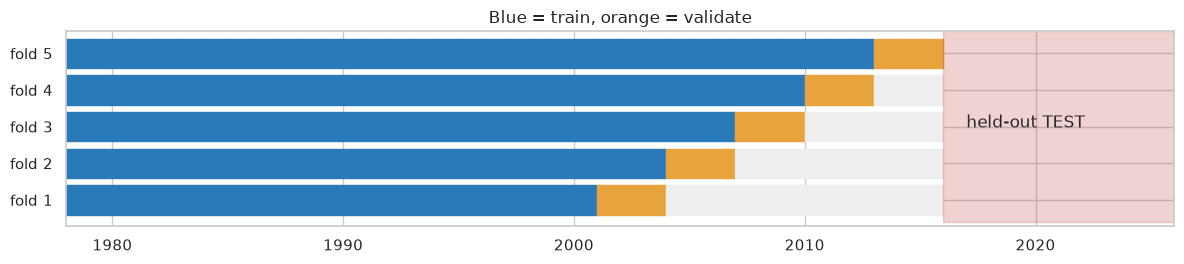

In [2]:
folds = expanding_window_cv(train)
fig, ax = plt.subplots(figsize=(12, 2.8))
years = np.arange(train.season_year.min(), C.TRAIN_END + 1)
for i, (tr, va) in enumerate(folds):
    tr_y, va_y = set(train.season_year.iloc[tr]), set(train.season_year.iloc[va])
    for y in years:
        ax.add_patch(plt.Rectangle((y, i), 1, .8, color="#2a7ab9" if y in tr_y else "#e8a33d" if y in va_y else "#eee"))
ax.add_patch(plt.Rectangle((C.TRAIN_END + 1, -0.2), df.season_year.max() - C.TRAIN_END, len(folds) + .2, color="#c0504d", alpha=.25))
ax.text(C.TRAIN_END + 2, len(folds) / 2, "held-out TEST", va="center")
ax.set_xlim(years[0], df.season_year.max() + 1); ax.set_ylim(-.3, len(folds)); ax.set_yticks(np.arange(len(folds)) + .4)
ax.set_yticklabels([f"fold {i+1}" for i in range(len(folds))]); ax.set_title("Blue = train, orange = validate")
plt.tight_layout(); plt.savefig(FIG / "cv_scheme.png", dpi=150); plt.show()

## 2. Preprocessing pipeline
* Numeric: median imputation **+ missing-indicator** → `StandardScaler` (scaling only for distance/margin based models: Ridge, KNN, SVR).
* Categorical (`district`, `season`): one-hot encoded.
* Everything is inside a `Pipeline`, so imputation and scaling are fitted on each CV training fold only (no preprocessing leakage).
* **Excluded on purpose:** harvested extent and production, which are only known after harvest (target leakage).

In [3]:
pre = make_preprocessor(features)
Xt = pre.fit_transform(train[features])
print("transformed shape:", Xt.shape)
Xt.iloc[:3, :12]

transformed shape: (1784, 65)


,season_year,fertilizer_crisis,prev_yield_same,prev_yield_any,yield_mean3_same,sown_ha,sown_change_pct,rain_total,rain_establish,rain_late,rain_days,rain_max5d
0,-1.730677,0.0,-0.011041,-0.015205,-0.023553,1.502250,-0.103816,-0.110918,-0.128491,-0.301335,-0.107423,-0.200416
1,-1.730677,0.0,-0.011041,-0.015205,-0.023553,3.296969,-0.103816,-0.110918,-0.128491,-0.301335,-0.107423,-0.200416
2,-1.730677,0.0,-0.011041,-0.015205,-0.023553,-0.100229,-0.103816,-0.110918,-0.128491,-0.301335,-0.107423,-0.200416


## 3. Models and hyperparameter search spaces
Every model is tuned with `RandomizedSearchCV` (sampling `N_ITER` combinations, scored by RMSE across the 5 time folds).

`uniform(loc, scale)` samples from [loc, loc + scale]; `loguniform(a, b)` samples evenly on a log scale between a and b (good for learning rate, C, α).

In [4]:
def show(v):
    if getattr(v, "dist", None):
        return (v.dist.name, v.args)
    if isinstance(v, list) and v and hasattr(v[0], "fit"):
        return [str(x) for x in v]
    return v

for name, (est, space) in model_zoo(features).items():
    print(f"{name}:")
    for j, sp in enumerate(space if isinstance(space, list) else [space]):
        if isinstance(space, list):
            print(f"  search space {j + 1}:")
        for k, v in sp.items():
            print(f"    {k.split('__')[-1]:20s} {show(v)}")

Ridge (baseline):
    alpha                ('loguniform', (0.001, 1000.0))
KNN:
    n_neighbors          ('randint', (3, 40))
    weights              ['uniform', 'distance']
SVR (RBF):
    C                    ('loguniform', (0.1, 100))
    gamma                ['scale', 0.001, 0.003, 0.01, 0.03]
    epsilon              ('uniform', (0.02, 0.3))
Decision Tree:
    max_depth            ('randint', (3, 16))
    min_samples_leaf     ('randint', (5, 60))
    ccp_alpha            ('loguniform', (0.1, 10000.0))
Random Forest:
    n_estimators         ('randint', (200, 700))
    max_depth            [None, 8, 12, 16, 24]
    max_features         ['sqrt', 0.33, 0.5, 0.8]
    min_samples_leaf     ('randint', (1, 12))
Gradient Boosting:
    n_estimators         ('randint', (200, 800))
    learning_rate        ('loguniform', (0.01, 0.2))
    max_depth            ('randint', (2, 6))
    subsample            ('uniform', (0.6, 0.4))
    min_samples_leaf     ('randint', (3, 30))
XGBoost:
    n_estim

| Model | Why it is in the comparison |
|---|---|
| Ridge | Linear baseline with L2 regularisation (Lecture 3); tests whether non-linearity is needed |
| KNN | Similarity-based: "seasons like this one had yields like…" |
| SVR (RBF) | Kernel method (Lecture 4); C and γ trade margin vs fit |
| Decision Tree | Interpretable single tree, cost-complexity pruning (Lecture 5) |
| Random Forest | Bagging + random feature subsets (Lecture 6); variance reduction |
| Gradient Boosting / XGBoost / LightGBM | Sequential residual fitting (Lecture 7); bias reduction; XGB/LGBM add L1/L2 regularisation |
| **NGBoost** (new, not covered in lectures) | Boosts the *parameters of a distribution* (mean μ and log σ of a Normal) with the natural gradient of the log-likelihood; tuned on CV **CRPS**. Gives intervals and P(shortfall). See section 9 |

In [5]:
N_ITER = 30
out = T.run(n_iter=N_ITER)
fitted, cv_table, test_table = out["fitted"], out["cv_table"], out["test_table"]
best_name, best_by_cv = out["best_name"], out["best_by_cv"]      # selected model (NGBoost) / best point model
fcs, prob_table = out["forecasters"], out["prob_table"]

Train 1784 rows (<= 2015), test 465 rows (> 2015); 23 features


Ridge (baseline)   CV RMSE   409.6 (+/- 67.1)  [4s]


KNN                CV RMSE   463.4 (+/- 60.2)  [2s]


SVR (RBF)          CV RMSE   411.3 (+/- 67.6)  [10s]


Decision Tree      CV RMSE   463.5 (+/- 78.5)  [3s]


Random Forest      CV RMSE   429.0 (+/- 68.1)  [232s]


... (3 outputs left out)

NGBoost            CV RMSE   409.8 (+/- 63.7)  CV CRPS  217.6  [403s]



Best point model by CV RMSE: Ridge (baseline) | selected for the early-warning system: NGBoost
                        model    RMSE     MAE  MAPE_%    R2  shortfall_precision  shortfall_recall  shortfall_F1
                    SVR (RBF) 578.756 435.996  12.290 0.606                0.500             0.038         0.070
                      XGBoost 618.251 456.956  13.017 0.551                0.500             0.025         0.048
            Gradient Boosting 625.585 461.073  13.171 0.540                0.400             0.025         0.047
                     LightGBM 632.303 459.263  13.116 0.530                0.500             0.025         0.048
                          KNN 651.232 500.751  13.671 0.501                0.393             0.138         0.204
             Ridge (baseline) 658.639 463.739  13.711 0.490                0.000             0.000         0.000
                Random Forest 661.647 483.966  13.596 0.485                0.375             0.038         0.068



Probabilistic forecasts (calibrated on CV, scored once on test):
                model  sigma_scale  prob_cut  cv_CRPS  cv_coverage_80  cv_shortfall_PR_AUC  cv_shortfall_F1  test_CRPS  test_CRPS_normal  test_NLL  test_coverage_80  test_coverage_95  test_width_80  test_shortfall_ROC_AUC  test_shortfall_PR_AUC  test_shortfall_Brier  test_shortfall_precision  test_shortfall_recall  test_shortfall_F1  test_shortfall_recall_normal  test_shortfall_F1_normal
              NGBoost         1.29      0.16  218.243           0.832                0.304            0.328    361.219           259.960     8.216             0.662             0.819       1047.556                   0.612                  0.249                 0.152                     0.255                  0.162              0.198                         0.286                     0.244
Ridge + Normal errors         1.00      0.23  220.831           0.848                0.266            0.305    351.200           256.956     8.206      


Saved models and metadata to artifacts/
MLflow tracking off (set MLFLOW_TRACKING_URI, or run as an Azure ML job).


## 4. Cross-validation results (model selection)

,model,cv_rmse,cv_rmse_std,cv_crps,tuning_seconds,best_params
0,Ridge (baseline),409.6,67.1,NaN,4.4,"{""alpha"": 17.71885}"
1,NGBoost,409.8,63.7,217.6,403.3,"{""Base"": ""Ridge(alpha=100.0)"", ""col_sample"": 1..."
2,SVR (RBF),411.3,67.6,NaN,10.0,"{""C"": 1.32929, ""epsilon"": 0.30521, ""gamma"": 0...."
3,Gradient Boosting,419.2,68.1,NaN,237.9,"{""learning_rate"": 0.05978, ""max_depth"": 3, ""mi..."
4,XGBoost,423.2,61.6,NaN,45.1,"{""colsample_bytree"": 0.84547, ""learning_rate"":..."
5,LightGBM,426.1,73.0,NaN,43.5,"{""colsample_bytree"": 0.91622, ""learning_rate"":..."
6,Random Forest,429.0,68.1,NaN,232.2,"{""max_depth"": null, ""max_features"": 0.8, ""min_..."
7,KNN,463.4,60.2,NaN,2.2,"{""n_neighbors"": 14, ""weights"": ""distance""}"
8,Decision Tree,463.5,78.5,NaN,2.7,"{""ccp_alpha"": 68.94482, ""max_depth"": 15, ""min_..."


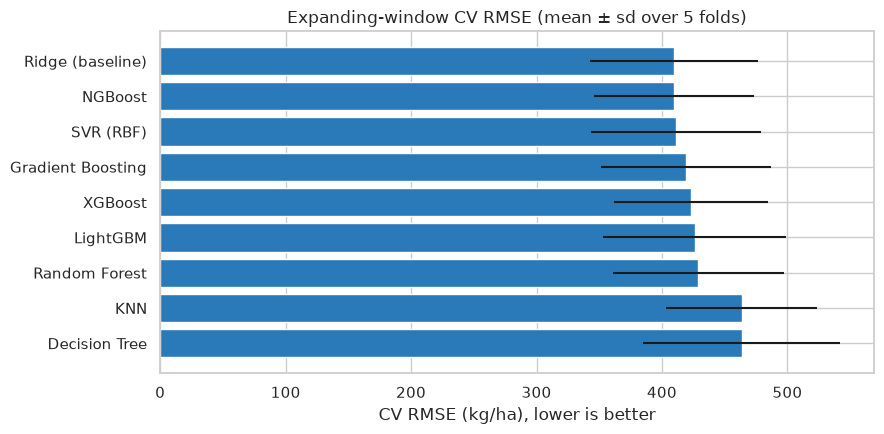

In [6]:
display(cv_table.round(1))
plt.figure(figsize=(9, 4.5))
plt.barh(cv_table.model, cv_table.cv_rmse, xerr=cv_table.cv_rmse_std, color="#2a7ab9")
plt.gca().invert_yaxis(); plt.xlabel("CV RMSE (kg/ha), lower is better")
plt.title("Expanding-window CV RMSE (mean ± sd over 5 folds)")
plt.tight_layout(); plt.savefig(FIG / "cv_rmse.png", dpi=150); plt.show()

## 5. Test-set evaluation (2016 onward, seen once)

In [7]:
display(test_table.round(3))

,model,RMSE,MAE,MAPE_%,R2,shortfall_precision,shortfall_recall,shortfall_F1
0,SVR (RBF),578.756,435.996,12.290,0.606,0.500,0.038,0.070
1,XGBoost,618.251,456.956,13.017,0.551,0.500,0.025,0.048
2,Gradient Boosting,625.585,461.073,13.171,0.540,0.400,0.025,0.047
3,LightGBM,632.303,459.263,13.116,0.530,0.500,0.025,0.048
4,KNN,651.232,500.751,13.671,0.501,0.393,0.138,0.204
5,Ridge (baseline),658.639,463.739,13.711,0.490,0.000,0.000,0.000
6,Random Forest,661.647,483.966,13.596,0.485,0.375,0.038,0.068
7,NGBoost,680.298,475.675,14.160,0.456,0.000,0.000,0.000
8,Decision Tree,728.344,537.008,14.957,0.376,0.130,0.038,0.058
9,Naive (last same-type season),758.791,552.623,15.543,0.323,NaN,NaN,NaN


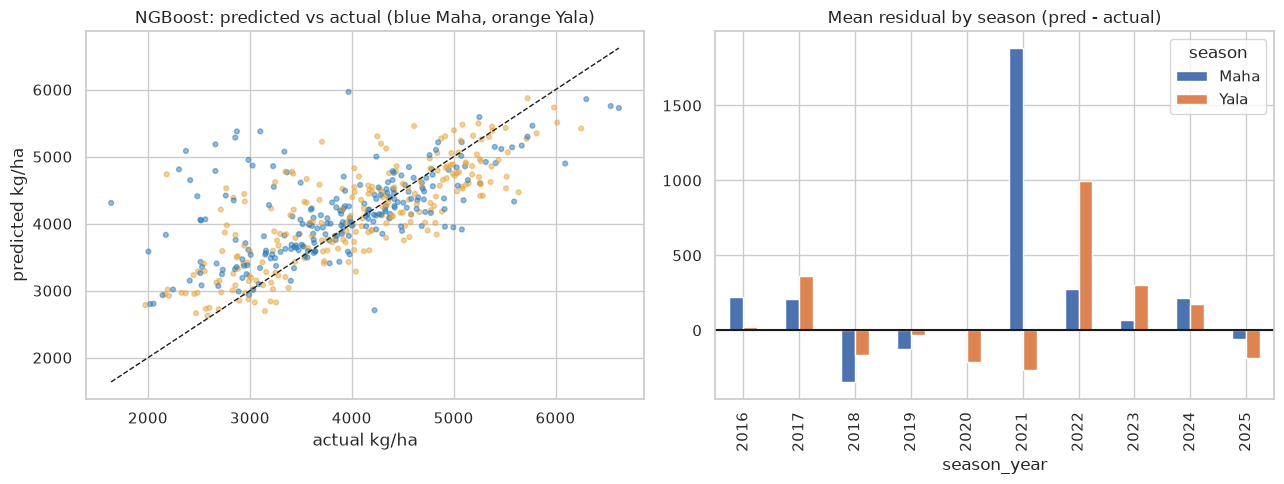

In [8]:
preds = pd.read_csv(C.ARTIFACTS / "test_predictions.csv")
best_col = "pred_" + T.slug(best_name)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(preds[TARGET], preds[best_col], s=12, alpha=.5, c=(preds.season == "Maha").map({True: "#2a7ab9", False: "#e8a33d"}))
lim = [preds[[TARGET, best_col]].min().min(), preds[[TARGET, best_col]].max().max()]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set_xlabel("actual kg/ha"); ax[0].set_ylabel("predicted kg/ha")
ax[0].set_title(f"{best_name}: predicted vs actual (blue Maha, orange Yala)")
res = preds.assign(res=preds[best_col] - preds[TARGET]).groupby(["season_year", "season"])["res"].mean().unstack()
res.plot.bar(ax=ax[1]); ax[1].axhline(0, c="k"); ax[1].set_title("Mean residual by season (pred - actual)")
plt.tight_layout(); plt.savefig(FIG / "test_pred_vs_actual.png", dpi=150); plt.show()

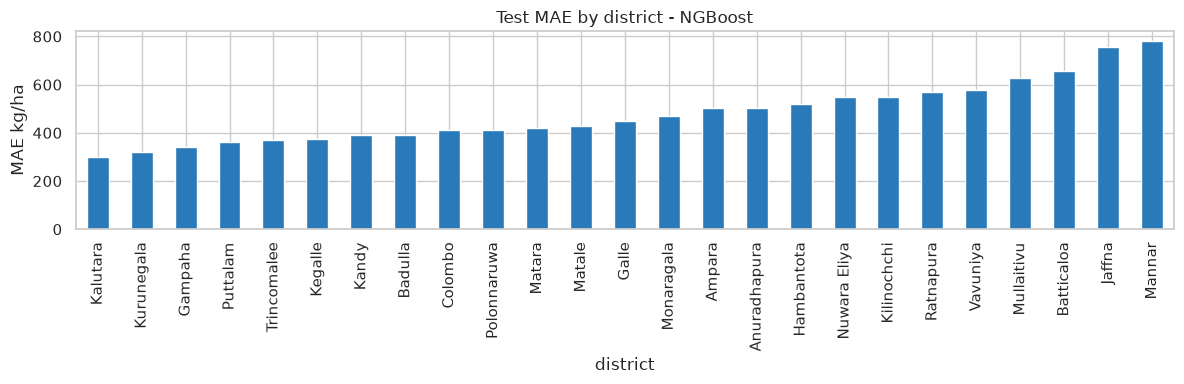

In [9]:
by_d = (preds.assign(abs_err=(preds[best_col] - preds[TARGET]).abs())
         .groupby("district")["abs_err"].mean().sort_values())
plt.figure(figsize=(12, 4)); by_d.plot.bar(color="#2a7ab9")
plt.ylabel("MAE kg/ha"); plt.title(f"Test MAE by district - {best_name}")
plt.tight_layout(); plt.savefig(FIG / "test_mae_district.png", dpi=150); plt.show()

### Excluding the fertilizer-crisis seasons
The same metrics with the two shock seasons removed show how the models do in 'normal' years.

In [10]:
from src.modeling import regression_metrics
mask = ~preds.apply(lambda r: (r.season, r.season_year) in C.FERTILIZER_CRISIS, axis=1)
rows = [{"model": c.replace("pred_", ""), **regression_metrics(preds.loc[mask, TARGET], preds.loc[mask, c])}
        for c in preds.columns if c.startswith("pred_")]
pd.DataFrame(rows).sort_values("RMSE").round(3)

,model,RMSE,MAE,MAPE_%,R2
0,ridge_baseline,467.774,356.298,9.522,0.723
8,ngboost,472.377,361.184,9.731,0.717
6,xgboost,488.833,376.769,9.700,0.697
2,svr_rbf,492.921,374.363,9.652,0.692
7,lightgbm,494.346,374.064,9.594,0.691
5,gradient_boosting,496.746,380.608,9.816,0.688
4,random_forest,504.149,389.501,9.779,0.678
3,decision_tree,566.235,440.318,11.038,0.594
1,knn,590.423,455.959,11.436,0.559


## 6. Early-warning view: shortfall detection from a point forecast
A season is a *shortfall* when yield < 85 % of the district's previous-5 same-season mean. Here the flag is raised only when the selected model's **point forecast** (its expected yield) falls below that threshold, as any regression model would do. Section 9 replaces this with the NGBoost **probability** of shortfall.

{'shortfall_cases': 80, 'precision': 0.0, 'recall': 0.0, 'F1': 0.0}


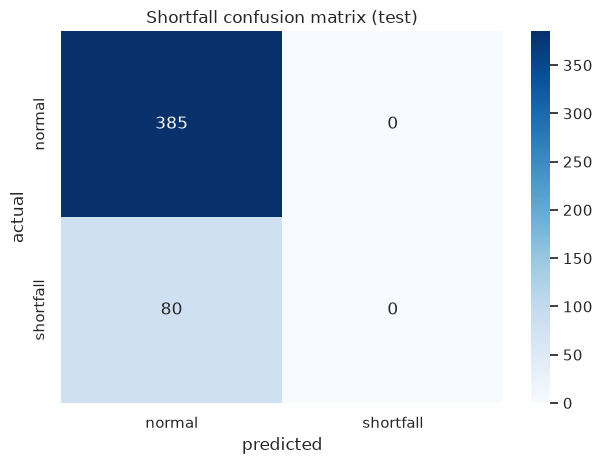

In [11]:
sm = shortfall_metrics(test, test[TARGET], fitted[best_name].predict(test[features]))
print({k: round(v, 3) if isinstance(v, float) else v for k, v in sm.items() if k != "confusion"})
cm = np.array(sm["confusion"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["normal", "shortfall"], yticklabels=["normal", "shortfall"])
plt.xlabel("predicted"); plt.ylabel("actual"); plt.title("Shortfall confusion matrix (test)")
plt.tight_layout(); plt.savefig(FIG / "shortfall_confusion.png", dpi=150); plt.show()

## 7. Bias-variance check for the chosen model
Train vs CV error: a large gap → overfitting (high variance); both high → underfitting (high bias).

In [12]:
from sklearn.metrics import mean_squared_error
rows = []
for name, m in fitted.items():
    tr_rmse = mean_squared_error(train[TARGET], m.predict(train[features])) ** .5
    rows.append({"model": name, "train_RMSE": tr_rmse, "cv_RMSE": float(cv_table.set_index("model").loc[name, "cv_rmse"])})
bv = pd.DataFrame(rows).assign(gap=lambda d: d.cv_RMSE - d.train_RMSE).sort_values("cv_RMSE")
display(bv.round(1))

,model,train_RMSE,cv_RMSE,gap
0,Ridge (baseline),396.3,409.6,13.3
8,NGBoost,394.7,409.8,15.2
2,SVR (RBF),399.7,411.3,11.6
5,Gradient Boosting,284.2,419.2,135.0
6,XGBoost,263.6,423.2,159.7
7,LightGBM,281.9,426.1,144.2
4,Random Forest,192.0,429.0,237.1
1,KNN,0.0,463.4,463.4
3,Decision Tree,386.3,463.5,77.1


## 8. Tuned hyperparameters of the selected model

In [13]:
params = cv_table.set_index("model").loc[best_name, "best_params"]
print("Selected model:", best_name, "| best point model by CV RMSE:", best_by_cv)
print(json.dumps(json.loads(params), indent=2))
print("Variance calibration factor k (from out-of-fold CV):", round(fcs[best_name]["sigma_scale"], 3))
print("Shortfall probability cut-off (max F1 on out-of-fold CV):", fcs[best_name]["cut"])

Selected model: NGBoost | best point model by CV RMSE: Ridge (baseline)
{
  "Base": "Ridge(alpha=100.0)",
  "col_sample": 1.0,
  "learning_rate": 0.02858,
  "minibatch_frac": 0.89259,
  "n_estimators": 150
}
Variance calibration factor k (from out-of-fold CV): 1.29
Shortfall probability cut-off (max F1 on out-of-fold CV): 0.16


## 9. NGBoost: a probabilistic forecast and the probability of shortfall

**Why this algorithm.** The planner's question is *"how likely is a shortfall in this district this season?"*. A point model (Ridge, XGBoost, …) gives one number, so a shortfall flag can only be raised when the forecast itself drops below the threshold, which almost never happens because forecasts stay close to recent yields. NGBoost (Duan et al., 2020, *NGBoost: Natural Gradient Boosting for Probabilistic Prediction*) predicts a distribution $Y \mid x \sim \mathcal{N}(\mu(x), \sigma(x))$, so

$$P(\text{shortfall}) = P\big(Y < 0.85\,\bar y_5\big) = \Phi\!\left(\frac{0.85\,\bar y_5 - \mu(x)}{\sigma(x)}\right).$$

**How it differs from the models in the lectures.**

| | Decision tree / Random forest / Gradient boosting / XGBoost | NGBoost |
|---|---|---|
| Output | one number (the mean) | a distribution: μ(x) **and** σ(x) for every row |
| What is boosted | residuals of squared error | the *parameters* (μ, log σ) of the distribution, one base learner per parameter per stage |
| Gradient | ordinary gradient of the loss | **natural gradient**: the gradient rescaled by the inverse Fisher information, so μ and σ learn at comparable speed whatever their scale |
| Loss | squared error | a proper scoring rule (here the log score, i.e. negative log-likelihood) |
| Uncertainty | none (or bolt-on, e.g. quantile models) | built in and **heteroscedastic**: σ changes with district, season and weather |

**Tuning.** The base learner itself is a hyperparameter (shallow trees *or* a ridge regression), together with the number of stages, learning rate, row subsampling (`minibatch_frac`) and column subsampling (`col_sample`). The search is scored on **CRPS** (continuous ranked probability score, in kg/ha), which rewards forecasts that are both accurate and appropriately confident; CV RMSE of the same candidates is recorded for comparison.

**Calibration and decision threshold, chosen on training seasons only.** (1) A variance-inflation factor *k* makes the out-of-fold standardised errors have unit variance (future seasons are harder than in-sample ones). (2) The probability cut-off for raising a shortfall flag maximises F1 on the out-of-fold predictions. The test seasons are used once, for the final evaluation.

**Fair comparison.** NGBoost is compared with the best point model (Ridge) turned into a probabilistic forecast by adding Normal errors whose σ is the Ridge out-of-fold RMSE (*Ridge + Normal errors*), calibrated and thresholded in exactly the same way.

In [14]:
from src.probabilistic import Z80
s = out["results"]["NGBoost"]["search"]
cvr = pd.DataFrame(s.cv_results_)
cvr["base learner"] = cvr["param_model__Base"].astype(str).str.replace(r"\(.*\)", "", regex=True)
cvr["base learner"] = np.where(cvr["base learner"] == "Ridge", "ridge (linear)", "shallow tree")
summary = (cvr.assign(cv_CRPS=-cvr.mean_test_crps, cv_RMSE=-cvr.mean_test_rmse)
              .groupby("base learner")[["cv_CRPS", "cv_RMSE"]].agg(["min", "median", "count"]).round(1))
display(summary)
print("Best NGBoost configuration:", {k.split("__")[-1]: v for k, v in s.best_params_.items()})

cv_CRPS              cv_RMSE             
                   min median count     min median count
base learner                                            
ridge (linear)   217.6  222.4    15   409.8  415.1    15
shallow tree     231.1  250.9    15   423.0  430.6    15

Best NGBoost configuration: {'Base': Ridge(alpha=100.0), 'col_sample': 1.0, 'learning_rate': np.float64(0.028580510658069373), 'minibatch_frac': np.float64(0.8925879806965068), 'n_estimators': 150}


### 9.1 Probabilistic comparison: NGBoost vs Ridge + Normal errors
`cv_*` columns are out-of-fold scores on the training seasons (used for calibration and the cut-off); `test_*` columns are the held-out seasons 2016 onward, looked at once.

In [15]:
display(prob_table.set_index("model").T.round(3))

model,NGBoost,Ridge + Normal errors
sigma_scale,1.290,1.000
prob_cut,0.160,0.230
cv_CRPS,218.243,220.831
cv_coverage_80,0.832,0.848
cv_shortfall_PR_AUC,0.304,0.266
cv_shortfall_F1,0.328,0.305
test_CRPS,361.219,351.200
test_CRPS_normal,259.960,256.956
test_NLL,8.216,8.206
test_coverage_80,0.662,0.695


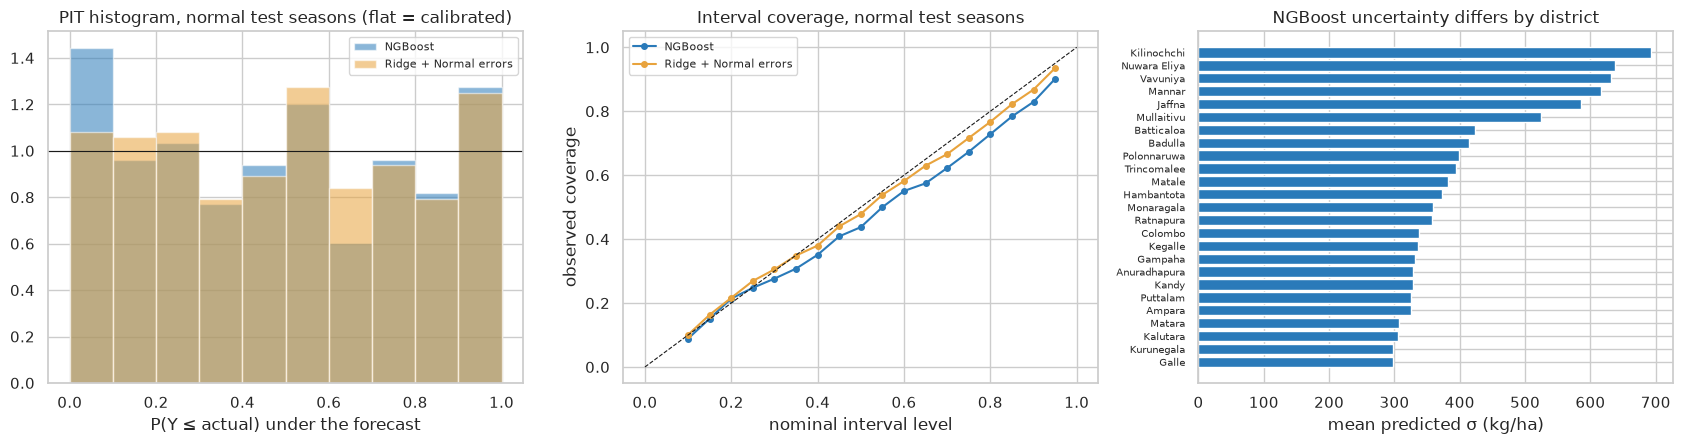

In [16]:
preds = pd.read_csv(C.ARTIFACTS / "test_predictions.csv")
crisis = preds.apply(lambda r: (r.season, r.season_year) in C.FERTILIZER_CRISIS, axis=1).to_numpy()
from scipy.stats import norm
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
# (a) PIT histogram: a calibrated forecast gives a flat histogram
for name, col, colour in [("NGBoost", "ngboost", "#2a7ab9"), ("Ridge + Normal errors", "ridge_normal_errors", "#e8a33d")]:
    mu = preds["pred_ngboost"] if col == "ngboost" else preds["pred_ridge_baseline"]
    pit = norm.cdf((preds[TARGET] - mu) / preds[f"sigma_{col}"])
    ax[0].hist(pit[~crisis], bins=10, range=(0, 1), alpha=.55, color=colour, label=name, density=True)
    levels = np.linspace(.1, .95, 18)
    cov = [np.mean(np.abs(preds[TARGET] - mu)[~crisis] <= norm.ppf(.5 + l / 2) * preds[f"sigma_{col}"][~crisis]) for l in levels]
    ax[1].plot(levels, cov, "o-", color=colour, label=name, ms=4)
ax[0].axhline(1, c="k", lw=.8); ax[0].set_title("PIT histogram, normal test seasons (flat = calibrated)")
ax[0].set_xlabel("P(Y ≤ actual) under the forecast"); ax[0].legend(fontsize=8)
ax[1].plot([0, 1], [0, 1], "k--", lw=.8); ax[1].set_xlabel("nominal interval level"); ax[1].set_ylabel("observed coverage")
ax[1].set_title("Interval coverage, normal test seasons"); ax[1].legend(fontsize=8)
# (c) heteroscedasticity: NGBoost sigma by district
sig = preds.groupby("district")["sigma_ngboost"].mean().sort_values()
ax[2].barh(sig.index, sig.values, color="#2a7ab9"); ax[2].set_xlabel("mean predicted σ (kg/ha)")
ax[2].set_title("NGBoost uncertainty differs by district"); ax[2].tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.savefig(FIG / "ngb_calibration.png", dpi=150); plt.show()

### 9.2 Early warning: how well does P(shortfall) separate shortfall seasons?

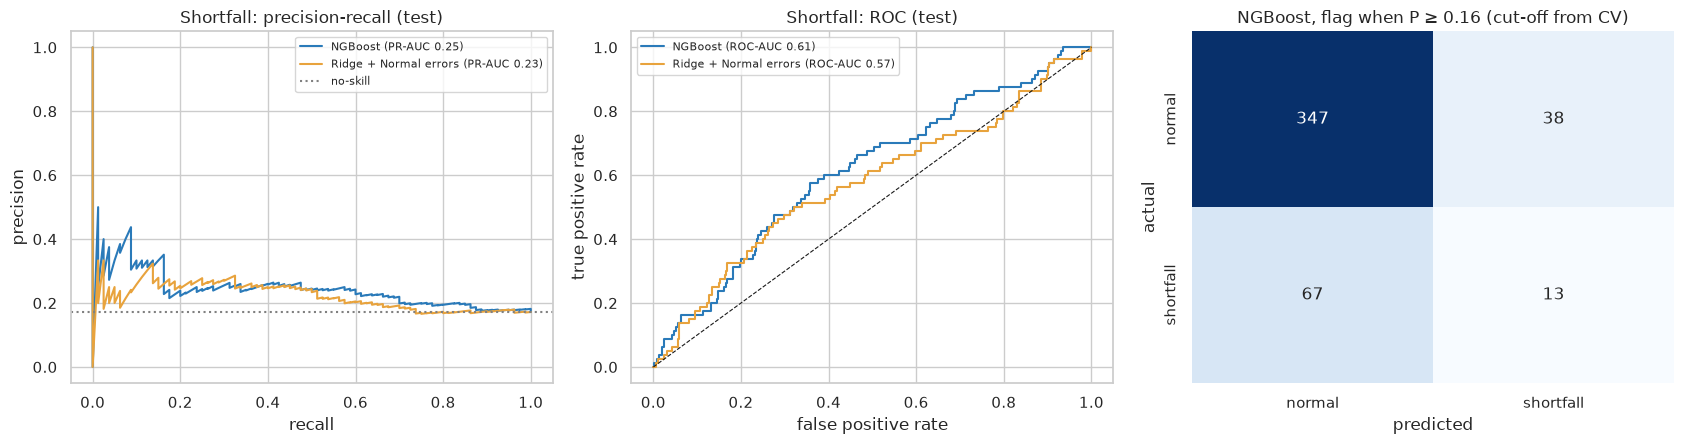

Point-forecast flag of the same NGBoost model (forecast < threshold): {'shortfall_cases': 80, 'precision': 0.0, 'recall': 0.0, 'F1': 0.0}


In [17]:
from sklearn.metrics import precision_recall_curve, roc_curve, confusion_matrix
from src.probabilistic import shortfall_truth
truth = shortfall_truth(preds.rename(columns={}), TARGET)
ok = ~np.isnan(truth)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for name, col, colour in [("NGBoost", "ngboost", "#2a7ab9"), ("Ridge + Normal errors", "ridge_normal_errors", "#e8a33d")]:
    p = preds[f"p_shortfall_{col}"].to_numpy()
    pr, rc, _ = precision_recall_curve(truth[ok], p[ok]); fpr, tpr, _ = roc_curve(truth[ok], p[ok])
    row = prob_table.set_index("model").loc[name]
    ax[0].plot(rc, pr, color=colour, label=f"{name} (PR-AUC {row.test_shortfall_PR_AUC:.2f})")
    ax[1].plot(fpr, tpr, color=colour, label=f"{name} (ROC-AUC {row.test_shortfall_ROC_AUC:.2f})")
ax[0].axhline(truth[ok].mean(), c="grey", ls=":", label="no-skill"); ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision")
ax[0].set_title("Shortfall: precision-recall (test)"); ax[0].legend(fontsize=8)
ax[1].plot([0, 1], [0, 1], "k--", lw=.8); ax[1].set_xlabel("false positive rate"); ax[1].set_ylabel("true positive rate")
ax[1].set_title("Shortfall: ROC (test)"); ax[1].legend(fontsize=8)
cut = fcs[best_name]["cut"]
cm = confusion_matrix(truth[ok].astype(int), (preds["p_shortfall_ngboost"].to_numpy()[ok] >= cut).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[2], cbar=False,
            xticklabels=["normal", "shortfall"], yticklabels=["normal", "shortfall"])
ax[2].set_xlabel("predicted"); ax[2].set_ylabel("actual"); ax[2].set_title(f"NGBoost, flag when P ≥ {cut:.2f} (cut-off from CV)")
plt.tight_layout(); plt.savefig(FIG / "ngb_shortfall_pr.png", dpi=150); plt.show()
print("Point-forecast flag of the same NGBoost model (forecast < threshold):",
      {k: round(v, 3) for k, v in shortfall_metrics(test, test[TARGET], fitted[best_name].predict(test[features])).items() if k != "confusion"})

### 9.3 What the forecast looks like for one district

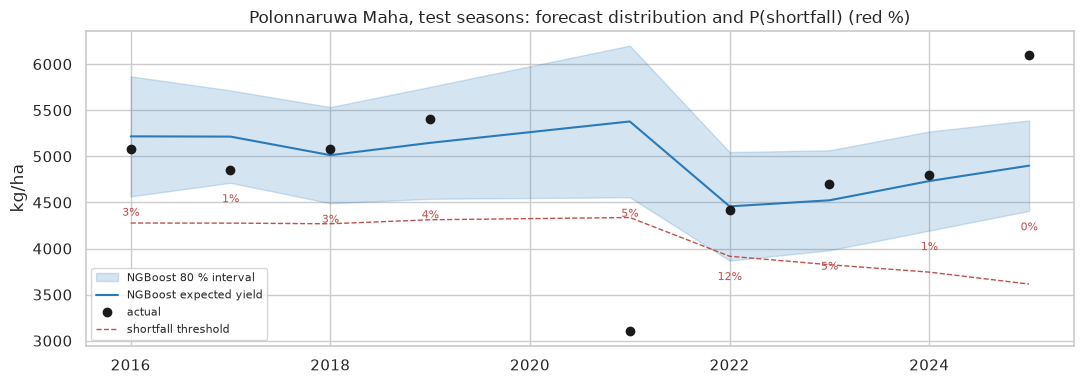

In [18]:
ex_d, ex_s = "Polonnaruwa", "Maha"
g = preds[(preds.district == ex_d) & (preds.season == ex_s)].sort_values("season_year")
fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(g.season_year, g.pred_ngboost - Z80 * g.sigma_ngboost, g.pred_ngboost + Z80 * g.sigma_ngboost,
                color="#2a7ab9", alpha=.2, label="NGBoost 80 % interval")
ax.plot(g.season_year, g.pred_ngboost, "-", color="#2a7ab9", label="NGBoost expected yield")
ax.plot(g.season_year, g[TARGET], "ko", label="actual")
ax.plot(g.season_year, C.SHORTFALL_THRESHOLD * g.yield_mean5_same, "--", c="#c0504d", lw=1, label="shortfall threshold")
for _, r in g.iterrows():
    ax.annotate(f"{100 * r.p_shortfall_ngboost:.0f}%", (r.season_year, r.pred_ngboost - Z80 * r.sigma_ngboost),
                textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8, color="#c0504d")
ax.set_ylabel("kg/ha"); ax.set_title(f"{ex_d} {ex_s}, test seasons: forecast distribution and P(shortfall) (red %)")
ax.legend(fontsize=8, loc="lower left"); plt.tight_layout(); plt.savefig(FIG / "ngb_forecast_example.png", dpi=150); plt.show()

### 9.4 Interpretation

**Which NGBoost won**

- Ridge base learners beat shallow trees: best CV CRPS 217.6 against 231.1 kg/ha.
- With about 1,800 training rows, a regularised linear model generalises best, as in section 4.
- With ridge learners NGBoost is a heteroscedastic linear model: μ is linear, like Ridge, and σ changes with district, season and weather.

**Why it was selected (training seasons only)**

- Lowest CV CRPS: 218.2 against 220.8 for Ridge + Normal errors.
- Same point error: CV RMSE 409.8 against 409.6.
- Better out-of-fold shortfall detection: PR-AUC 0.30 against 0.27, F1 0.33 against 0.31.
- It is the only model that gives each district-season its own uncertainty.

**Calibration**

- Raw intervals were too narrow for future seasons, so σ is scaled by k = 1.29 (estimated on the CV folds).
- Out-of-fold 80% coverage is then 0.83.
- On the test seasons it is 0.73 in normal seasons and 0.10 in the crisis seasons.

**Early warning on the test seasons**

| | NGBoost P(shortfall) | Ridge + Normal errors | NGBoost point forecast < threshold |
|---|---|---|---|
| ROC-AUC | **0.61** | 0.57 | n/a |
| Recall (shortfalls caught) | **16 %** | 6 % | 0 % |
| F1 | **0.20** | 0.10 | 0.00 |
| Recall, normal seasons only | **29 %** | 11 % | n/a |

- Used as a point forecast, the same model catches none of the 80 shortfalls.
- 45 of the 80 shortfalls are in the crisis seasons. The crisis flag is 0 in every training season, so NGBoost gives those rows an average P(shortfall) of only 5%.

**What it does not improve**

- Point accuracy is slightly worse than Ridge: test RMSE 680 against 659 (472 against 468 in normal seasons).
- Test CRPS is slightly worse too: 361 against 351 (260 against 257 in normal seasons).
- Its value is a probability and a range that a planner can act on, with uncertainty that is larger where the model is weaker: σ is about twice as large in Kilinochchi, Vavuniya and Mannar as in Galle or Kurunegala (notebook 03).